In [1]:
%load_ext autoreload
%autoreload 2

# Imports (sin aprendizaje automático: solo umbrales sobre las características del notebook 04)
import sys; sys.path.append("..")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

## 5.1 Datos de entrada y grupos de paciente

In [2]:
# CSV del notebook 04, solo con los cortes que pasaron el descarte de 4.2
CSV = Path("..") / "data" / "caracteristicas_cortes.csv"
feat = pd.read_csv(CSV)
SEG = ["Area_rel", "N_regiones", "Area_max_region"]
TEXT = ["Contraste", "Homogeneidad", "Energia", "Correlacion", "Entropia"]

datos = feat[feat["Pasa"]].dropna(subset=SEG + TEXT).reset_index(drop=True)
datos["y"] = (datos["Clase"] == "MS").astype(int)
print(f"{feat['Pasa'].sum()} cortes pasan el descarte; {len(datos)} sin NaN en las características")
datos.groupby(["Clase", "Eje"]).size().unstack()

2762 cortes pasan el descarte; 2760 sin NaN en las características


Eje,Axial,Sagital
Clase,,
Control,696,771
MS,584,709


In [3]:
# Grupos de "paciente", para que los cortes de un mismo sujeto no queden repartidos entre la parte con la que
# se fijan los umbrales y la parte con la que se evalúa la regla.
# - Control con ID: el ID real (compartido entre axial y sagital).
# - Control sin ID (149 axiales en dos series, "kontrol (n)" y "kontrol aks (n)"): bloques de 14 archivos consecutivos.
# - MS (sin ID): bloques de archivos consecutivos del contador, de tamaño cortes / 72 pacientes en cada eje.
#   APROXIMACIÓN: no se sabe si el contador sigue el orden de los pacientes.
N_PACIENTES_MS = 72
BLOQUE_CONTROL = 14

def grupos_aproximados(df, n_pac_ms=N_PACIENTES_MS, bloque_control=BLOQUE_CONTROL, inventario=None):
    inv = df if inventario is None else inventario
    g = pd.Series(index=df.index, dtype=object)
    ctrl = df["Clase"] == "Control"
    con_id = ctrl & df["IdNombre"].notna()
    g[con_id] = "C" + df.loc[con_id, "IdNombre"].astype(int).astype(str)
    sin_id = ctrl & df["IdNombre"].isna()
    serie = df.loc[sin_id, "Ruta"].str.contains("aks").map({True: "aks", False: "k"})
    g[sin_id] = "C_" + serie + "_" + ((df.loc[sin_id, "Corte"] - 1) // bloque_control).astype(str)
    for eje in ["Axial", "Sagital"]:
        ms = (df["Clase"] == "MS") & (df["Eje"] == eje)
        n_total = ((inv["Clase"] == "MS") & (inv["Eje"] == eje)).sum()
        tam = round(n_total / n_pac_ms)
        g[ms] = f"MS_{eje[0]}_" + ((df.loc[ms, "Corte"] - 1) // tam).astype(str)
    return g

# Partición en 5 por grupo: cada grupo entero va a una partición, al azar y por separado en cada clase
K, SEMILLA = 5, 0

def particion_por_grupo(grupos, y, k=K, semilla=SEMILLA):
    clase = pd.Series(y, index=grupos).groupby(level=0).first()
    rng = np.random.default_rng(semilla)
    particion = {}
    for c in sorted(clase.unique()):
        gs = np.array(sorted(clase[clase == c].index))
        rng.shuffle(gs)
        particion.update({g: i % k for i, g in enumerate(gs)})
    return pd.Series(grupos).map(particion).to_numpy()

datos["Grupo"] = grupos_aproximados(datos, inventario=feat)
datos["Particion"] = particion_por_grupo(datos["Grupo"].to_numpy(), datos["y"].to_numpy())
print(datos.groupby("Clase")["Grupo"].nunique().to_dict(), "grupos")
assert (datos.groupby("Grupo")["Particion"].nunique() == 1).all()     # ningún grupo partido
datos.groupby(["Particion", "Clase"]).size().unstack()

{'Control': 60, 'MS': 142} grupos


Clase,Control,MS
Particion,,
0,277,256
1,296,273
2,331,256
3,277,248
4,286,260


&ensp; La entrada es `data/caracteristicas_cortes.csv` (notebook 04), con los cortes que pasaron el descarte de 4.2: 2760 cortes sin NaN (1467 de Control y 1293 de MS). **La clasificación se hace con reglas de umbral sobre las características, sin aprendizaje automático**: no hay ningún modelo que ajuste pesos, solo se fija un valor de corte para una o dos características.

&ensp; Aunque una regla de umbral es simple, el umbral se calcula a partir de los datos. Si se calculara y se evaluara con los mismos cortes, el rendimiento saldría optimista. Por eso se usa una **validación cruzada por grupos**: los cortes se reparten en 5 particiones, el umbral se calcula con 4 y la regla se evalúa en la restante, rotando. Para que los cortes de un mismo paciente no queden de los dos lados, cada **grupo de paciente** va entero a una sola partición:

- **Control con ID** (48 sujetos): el ID real, compartido entre axial y sagital.
- **Control sin ID** (149 axiales en dos series): bloques de 14 archivos consecutivos (149 cortes / 11 sujetos).
- **MS** (sin ID): bloques de archivos consecutivos del contador, de 9 en axial (650 / 72) y 11 en sagital (761 / 72).

&ensp; Resultan 60 grupos de Control y 142 de MS, asignados al azar (semilla 0) a las 5 particiones, por separado en cada clase. Cada partición tiene entre 248 y 331 cortes por clase.

**Limitaciones.** Los grupos de MS son una aproximación: no se sabe si el contador sigue el orden de los pacientes, y la reconstrucción por saltos de tamaño del notebook 01 se refutó. En MS, el axial y el sagital de un mismo paciente quedan en grupos distintos.

## 5.2 Capacidad de cada característica por separado

In [4]:
# AUC de cada característica usada sola como puntaje, por eje: probabilidad de que un corte de MS al azar tenga
# un valor mayor que uno de Control al azar (= U de Mann-Whitney / (n_MS * n_Control) = CLES del notebook 04).
# Si la característica es menor en MS, se usa 1 - AUC y el sentido de la regla es "<".
def auc(y, puntaje):
    y = np.asarray(y)
    u, _ = mannwhitneyu(puntaje[y == 1], puntaje[y == 0], alternative="two-sided")
    return u / ((y == 1).sum() * (y == 0).sum())

filas = []
for c in SEG + TEXT:
    fila = {"Caracteristica": c}
    for eje in ["Axial", "Sagital"]:
        d = datos[datos["Eje"] == eje]
        a = auc(d["y"].to_numpy(), d[c].to_numpy())
        fila[f"AUC {eje}"] = max(a, 1 - a)
        fila["Sentido"] = ">" if a >= 0.5 else "<"
    filas.append(fila)
capacidad = pd.DataFrame(filas).set_index("Caracteristica")
capacidad.sort_values("AUC Axial", ascending=False).round(3)

,AUC Axial,Sentido,AUC Sagital
Caracteristica,,,
Area_max_region,0.789,>,0.658
Area_rel,0.787,>,0.662
N_regiones,0.775,>,0.659
Entropia,0.715,>,0.702
Contraste,0.710,>,0.684
Homogeneidad,0.684,<,0.660
Energia,0.664,<,0.651
Correlacion,0.570,<,0.561


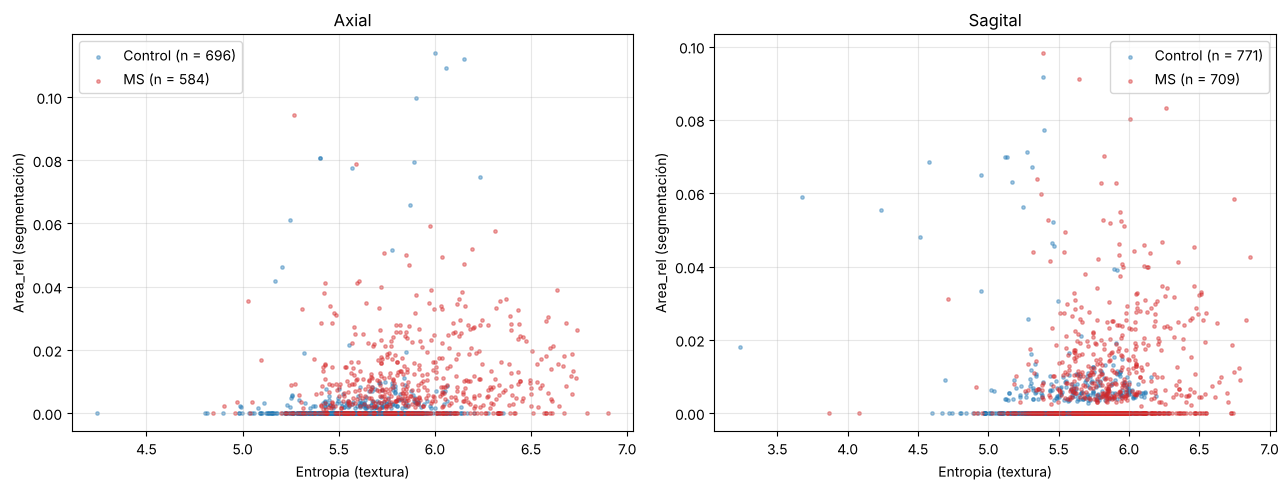

In [5]:
# Las dos mejores de cada bloque, una de segmentación y una de textura, en un diagrama de dispersión por eje
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, eje in zip(axs, ["Axial", "Sagital"]):
    for clase, color in [("Control", "tab:blue"), ("MS", "tab:red")]:
        d = datos[(datos["Eje"] == eje) & (datos["Clase"] == clase)]
        ax.scatter(d["Entropia"], d["Area_rel"], s=6, alpha=0.4, color=color, label=f"{clase} (n = {len(d)})")
    ax.set_xlabel("Entropia (textura)"); ax.set_ylabel("Area_rel (segmentación)")
    ax.set_title(eje); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

&ensp; Antes de fijar umbrales, se mide cuánto separa cada característica por sí sola con el **AUC**: la probabilidad de que un corte de MS tomado al azar tenga un valor mayor que uno de Control (o menor, si la característica es menor en MS). Es el U de Mann-Whitney dividido por n_MS · n_Control, es decir, el **CLES del notebook 04**. Tiene la ventaja de no depender de ningún umbral: 0,5 significa que la característica no separa las clases y 1, que las separa perfectamente.

| Característica | AUC axial | AUC sagital |
|---|---|---|
| Area_max_region | 0,789 | 0,658 |
| Area_rel | 0,787 | 0,662 |
| N_regiones | 0,775 | 0,659 |
| Entropía | 0,715 | 0,702 |
| Contraste | 0,710 | 0,684 |
| Homogeneidad (menor en MS) | 0,684 | 0,660 |
| Energía (menor en MS) | 0,664 | 0,651 |
| Correlación (menor en MS) | 0,570 | 0,561 |

**Elección.** Ninguna característica separa bien sola (AUC máximo de 0,79 en axial y 0,70 en sagital). Se toma la mejor de cada bloque, que además son poco redundantes entre sí (Spearman ≈ 0,24):
- de la segmentación, **`Area_rel`**: rinde prácticamente igual que `Area_max_region` y es más fácil de interpretar, porque es la fracción del cerebro marcada como lesión;
- de la textura, **entropía**: es la mejor del bloque en los dos ejes.

&ensp; El diagrama de dispersión muestra por qué no alcanza un umbral: los cortes de las dos clases se superponen mucho. Muchos cortes de MS tienen `Area_rel` = 0 (no se segmentó nada), pero algunos de ellos tienen entropía alta, y al revés.

## 5.3 Criterio para fijar los umbrales

In [6]:
# Dos criterios para fijar el umbral de una característica, en cada eje:
# - "percentil": percentil 95 de los controles (el control negativo del notebook 04). Fija de antemano una tasa de
#   falsos positivos de ~5 % por característica y no usa los cortes de MS.
# - "youden": el valor que maximiza sensibilidad + especificidad - 1, probando los percentiles 1 a 99.
# Los umbrales se calculan solo con las particiones de entrenamiento y la regla se evalúa en la de prueba.
P_CONTROL = 95

def umbral_percentil(valores_control, sentido=">", p=P_CONTROL):
    return np.percentile(valores_control, p if sentido == ">" else 100 - p)

def umbral_youden(valores, y, sentido=">"):
    mejor, umbral = -np.inf, None
    for u in np.percentile(valores, np.arange(1, 100)):
        pred = valores > u if sentido == ">" else valores < u
        j = pred[y == 1].mean() - pred[y == 0].mean()
        if j > mejor:
            mejor, umbral = j, u
    return umbral

def ajustar_umbrales(df, regla, criterio="percentil", p=P_CONTROL):
    umbrales = {}
    for eje in ["Axial", "Sagital"]:
        d = df[df["Eje"] == eje]
        for c, s in regla:
            if criterio == "percentil":
                umbrales[(eje, c)] = umbral_percentil(d.loc[d["y"] == 0, c].to_numpy(), s, p)
            else:
                umbrales[(eje, c)] = umbral_youden(d[c].to_numpy(), d["y"].to_numpy(), s)
    return umbrales

def aplicar_regla(df, umbrales, regla, combinar="o"):
    votos = []
    for c, s in regla:
        u = np.array([umbrales[(e, c)] for e in df["Eje"]])
        votos.append(df[c].to_numpy() > u if s == ">" else df[c].to_numpy() < u)
    votos = np.vstack(votos)
    return votos.any(axis=0) if combinar == "o" else votos.all(axis=0)

def validar(df, particion, regla, criterio="percentil", combinar="o", p=P_CONTROL):
    pred = np.zeros(len(df), bool)
    for k in np.unique(particion):
        te = particion == k
        u = ajustar_umbrales(df[~te], regla, criterio, p)
        pred[te] = aplicar_regla(df[te], u, regla, combinar)
    return pred

def metricas(y, pred):
    y, pred = np.asarray(y), np.asarray(pred, bool)
    tp, fn = int((pred & (y == 1)).sum()), int((~pred & (y == 1)).sum())
    tn, fp = int((~pred & (y == 0)).sum()), int((pred & (y == 0)).sum())
    sens, esp = tp / (tp + fn), tn / (tn + fp)
    return {"Sensibilidad": sens, "Especificidad": esp, "Exactitud balanceada": (sens + esp) / 2,
            "TP": tp, "FN": fn, "TN": tn, "FP": fp}

In [7]:
# Reglas de una característica y combinaciones de una de segmentación con una de textura
REGLAS = {
    "Area_rel":                 ([("Area_rel", ">")], "o"),
    "Area_max_region":          ([("Area_max_region", ">")], "o"),
    "Entropia":                 ([("Entropia", ">")], "o"),
    "Homogeneidad":             ([("Homogeneidad", "<")], "o"),
    "Area_rel O Entropia":      ([("Area_rel", ">"), ("Entropia", ">")], "o"),
    "Area_rel Y Entropia":      ([("Area_rel", ">"), ("Entropia", ">")], "y"),
    "Area_rel O Homogeneidad":  ([("Area_rel", ">"), ("Homogeneidad", "<")], "o"),
}
y = datos["y"].to_numpy()
part = datos["Particion"].to_numpy()

filas, preds = [], {}
for criterio in ["percentil", "youden"]:
    for nombre, (regla, comb) in REGLAS.items():
        pred = validar(datos, part, regla, criterio, comb)
        preds[(criterio, nombre)] = pred
        filas.append({"Criterio": criterio, "Regla": nombre, **metricas(y, pred)})
res = pd.DataFrame(filas)
res[["Criterio", "Regla", "Sensibilidad", "Especificidad", "Exactitud balanceada"]].round(3)

,Criterio,Regla,Sensibilidad,Especificidad,Exactitud balanceada
0,percentil,Area_rel,0.360,0.948,0.654
1,percentil,Area_max_region,0.347,0.948,0.647
2,percentil,Entropia,0.319,0.951,0.635
3,percentil,Homogeneidad,0.297,0.950,0.624
4,percentil,Area_rel O Entropia,0.531,0.903,0.717
5,percentil,Area_rel Y Entropia,0.148,0.996,0.572
6,percentil,Area_rel O Homogeneidad,0.533,0.900,0.717
7,youden,Area_rel,0.529,0.829,0.679
8,youden,Area_max_region,0.574,0.797,0.685
9,youden,Entropia,0.497,0.802,0.650


&ensp; Se compararon dos criterios para fijar el umbral de cada característica, en cada eje por separado:

- **Percentil 95 de los controles.** El umbral es el valor que solo supera el 5 % de los cortes de Control. Retoma el **control negativo** del notebook 04: como los controles no tienen lesiones, se acepta de antemano una tasa de falsos positivos de alrededor del 5 % por característica. No usa los cortes de MS para fijar el umbral.
- **Índice de Youden.** El umbral que maximiza sensibilidad + especificidad − 1, buscado entre los percentiles 1 a 99. Usa las dos clases.

&ensp; Las reglas de dos características se combinan con «O» (es MS si cualquiera supera su umbral) o con «Y» (si las dos lo superan).

| Criterio | Regla | Sensibilidad | Especificidad | Exactitud balanceada |
|---|---|---|---|---|
| Percentil 95 | Area_rel | 0,360 | 0,948 | 0,654 |
| Percentil 95 | Entropía | 0,319 | 0,951 | 0,635 |
| Percentil 95 | **Area_rel O Entropía** | **0,531** | **0,903** | **0,717** |
| Percentil 95 | Area_rel Y Entropía | 0,148 | 0,996 | 0,572 |
| Youden | Area_rel | 0,529 | 0,829 | 0,679 |
| Youden | Entropía | 0,497 | 0,802 | 0,650 |
| Youden | Area_rel O Entropía | 0,752 | 0,673 | 0,713 |
| Youden | Area_rel Y Entropía | 0,275 | 0,958 | 0,616 |

**Resultados.**
- **Combinar con «O» una característica de segmentación y una de textura es lo que más rinde**, con los dos criterios: la exactitud balanceada sube de 0,61–0,69 con una sola característica a 0,70–0,72. Es coherente con que las dos estén poco correlacionadas: cada una detecta cortes de MS que la otra no ve. Cambiar entropía por homogeneidad da prácticamente lo mismo (0,717 con percentil y 0,699 con Youden).
- Combinar con «Y» es demasiado exigente: sube la especificidad pero pierde casi toda la sensibilidad.
- **Los dos criterios llegan a una exactitud balanceada casi igual** con la regla «O» (0,717 y 0,713), pero en puntos distintos: el percentil prioriza la especificidad (0,903) y Youden, la sensibilidad (0,752).

&ensp; Se eligió el **percentil 95 de los controles**. Tiene una justificación propia, independiente de los datos de MS (limitar los falsos positivos a ~5 % por característica), rinde igual que Youden y da umbrales más estables, porque no buscan el óptimo de cada partición de entrenamiento.

## 5.4 Regla elegida

In [8]:
# Regla elegida: un corte es MS si Area_rel O Entropia superan el percentil 95 de los controles de su eje.
# Umbrales finales, calculados con todos los cortes (son los que se reportan y se usan en el notebook 06)
REGLA = [("Area_rel", ">"), ("Entropia", ">")]
umbrales = ajustar_umbrales(datos, REGLA)
pd.Series(umbrales).unstack().round(4)

,Area_rel,Entropia
Axial,0.007,6.0005
Sagital,0.011,6.0083


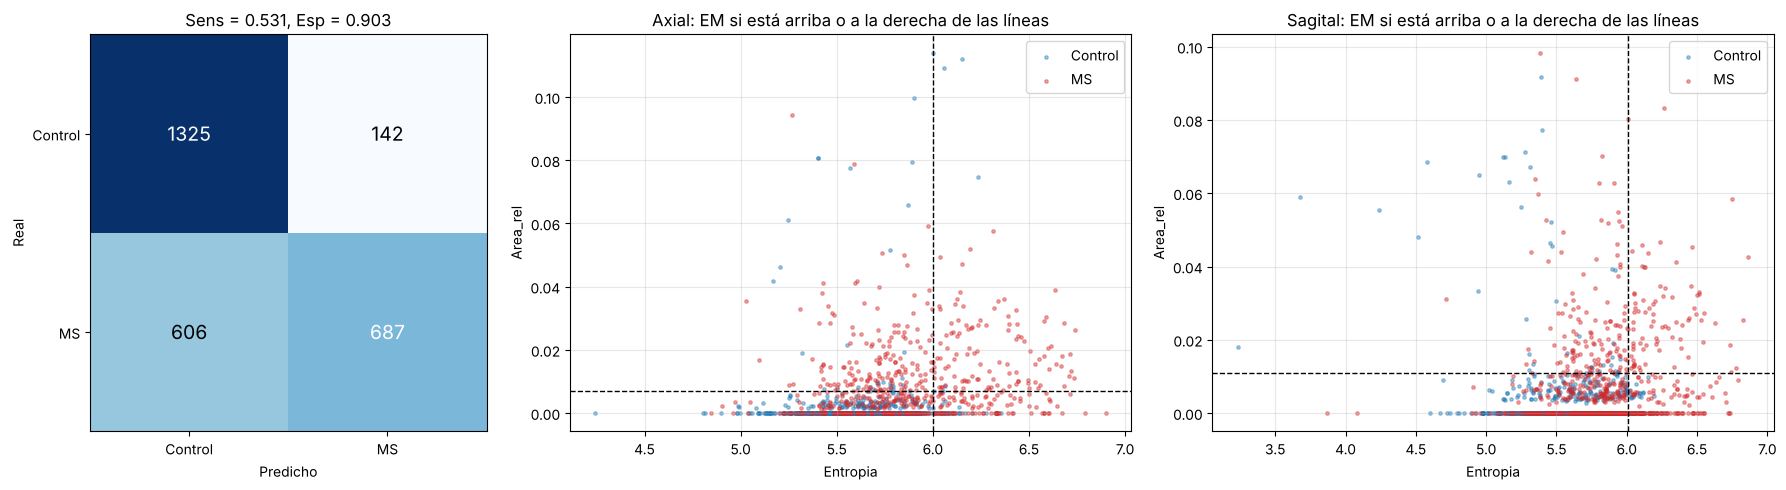

,Sensibilidad,Especificidad,Exactitud balanceada,TP,FN,TN,FP
Axial,0.618,0.908,0.763,361.0,223.0,632.0,64.0
Sagital,0.460,0.899,0.679,326.0,383.0,693.0,78.0


In [9]:
# Rendimiento en la validación por grupo (umbrales calculados sin la partición de prueba)
pred = preds[("percentil", "Area_rel O Entropia")]
m = metricas(y, pred)
cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])

fig, axs = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
axs[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axs[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
axs[0].set_xticks([0, 1], ["Control", "MS"]); axs[0].set_yticks([0, 1], ["Control", "MS"])
axs[0].set_xlabel("Predicho"); axs[0].set_ylabel("Real")
axs[0].set_title(f"Sens = {m['Sensibilidad']:.3f}, Esp = {m['Especificidad']:.3f}")
for ax, eje in zip(axs[1:], ["Axial", "Sagital"]):
    for clase, color in [("Control", "tab:blue"), ("MS", "tab:red")]:
        d = datos[(datos["Eje"] == eje) & (datos["Clase"] == clase)]
        ax.scatter(d["Entropia"], d["Area_rel"], s=6, alpha=0.4, color=color, label=clase)
    ax.axhline(umbrales[(eje, "Area_rel")], color="k", ls="--", lw=1)
    ax.axvline(umbrales[(eje, "Entropia")], color="k", ls="--", lw=1)
    ax.set_xlabel("Entropia"); ax.set_ylabel("Area_rel")
    ax.set_title(f"{eje}: EM si está arriba o a la derecha de las líneas")
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Rendimiento por eje
pd.DataFrame({eje: metricas(y[datos["Eje"] == eje], pred[datos["Eje"] == eje]) for eje in ["Axial", "Sagital"]}).T.round(3)

In [10]:
# ¿Qué característica dispara la regla? (con los umbrales finales)
a = datos["Area_rel"] > datos["Eje"].map({e: umbrales[(e, "Area_rel")] for e in ["Axial", "Sagital"]})
e = datos["Entropia"] > datos["Eje"].map({x: umbrales[(x, "Entropia")] for x in ["Axial", "Sagital"]})
motivo = np.select([a & e, a, e], ["Las dos", "Solo Area_rel", "Solo Entropia"], "Ninguna")
pd.crosstab(datos["Clase"], motivo, margins=True)

col_0,Las dos,Ninguna,Solo Area_rel,Solo Entropia,All
Clase,,,,,
Control,5,1324,69,69,1467
MS,190,604,279,220,1293
All,195,1928,348,289,2760


&ensp; La regla final es:

> **Un corte es MS si `Area_rel` > U₁ o entropía > U₂**, con U₁ y U₂ iguales al percentil 95 de los controles de su eje.

| Eje | U₁ (Area_rel) | U₂ (Entropía) |
|---|---|---|
| Axial | 0,0070 | 6,0005 |
| Sagital | 0,0110 | 6,0083 |

&ensp; Los umbrales de `Area_rel` coinciden con el percentil 95 de los controles reportado en 4.4: son el límite de los falsos positivos de la segmentación. Estos son los umbrales calculados con todos los cortes, que se usan en el notebook 06. El rendimiento reportado abajo es el de la validación por grupo, con umbrales calculados sin la partición de prueba.

**Rendimiento global:** sensibilidad = 0,531 y especificidad = 0,903 (687 de 1293 cortes de MS detectados; 142 falsos positivos en 1467 cortes de Control).

| Eje | Sensibilidad | Especificidad | Exactitud balanceada |
|---|---|---|---|
| Axial | 0,618 | 0,908 | 0,763 |
| Sagital | 0,460 | 0,899 | 0,679 |

&ensp; Funciona mejor en **axial**, como en todo el análisis. La especificidad es casi igual en los dos ejes (≈ 0,90), como se espera de un umbral fijado sobre los controles: dos reglas de 5 % de falsos positivos combinadas con «O» dan como máximo ~10 %.

&ensp; Con los umbrales finales se detectan 689 cortes de MS: 279 solo por `Area_rel`, 220 solo por la entropía y 190 por las dos. **Cada característica aporta cortes que la otra no detecta**, lo que confirma que conviene combinarlas.

**Limitaciones.**
- **La sensibilidad es baja:** casi la mitad de los cortes de MS no se detecta. Es esperable, porque muchos cortes de MS no contienen lesiones visibles, pero significa que la regla **no sirve para descartar EM a partir de un corte**.
- El percentil 95 es una elección. Bajarlo (por ejemplo, a 90) aumentaría la sensibilidad a costa de más falsos positivos.
- La entropía puede estar captando diferencias de adquisición entre los grupos, y no solo cambios de la sustancia blanca (4.5).

## 5.5 Clasificación por paciente aproximado

In [11]:
# Para cada grupo, la fracción de sus cortes que la regla marca como MS (predicciones de la validación).
# El grupo es MS si esa fracción supera el percentil 95 de las fracciones de los grupos Control de entrenamiento.
g = pd.DataFrame({"Grupo": datos["Grupo"], "y": y, "pred": pred, "Particion": part})
grp = g.groupby("Grupo").agg(y=("y", "first"), frac=("pred", "mean"), n=("pred", "size"), Particion=("Particion", "first"))

grp["pred"] = False
umbral_frac = {}
for k in range(K):
    tr, te = grp["Particion"] != k, grp["Particion"] == k
    umbral_frac[k] = umbral_percentil(grp.loc[tr & (grp["y"] == 0), "frac"].to_numpy())
    grp.loc[te, "pred"] = grp.loc[te, "frac"] > umbral_frac[k]

print("Umbral de fracción por partición:", {k: round(v, 3) for k, v in umbral_frac.items()})
print(f"AUC por grupo (fracción como puntaje): {auc(grp['y'].to_numpy(), grp['frac'].to_numpy()):.3f}")
pd.DataFrame({"Corte": metricas(y, pred), "Grupo": metricas(grp["y"], grp["pred"])}).T.round(3)

Umbral de fracción por partición: {0: np.float64(0.266), 1: np.float64(0.246), 2: np.float64(0.273), 3: np.float64(0.246), 4: np.float64(0.246)}
AUC por grupo (fracción como puntaje): 0.875


,Sensibilidad,Especificidad,Exactitud balanceada,TP,FN,TN,FP
Corte,0.531,0.903,0.717,687.0,606.0,1325.0,142.0
Grupo,0.761,0.950,0.855,108.0,34.0,57.0,3.0


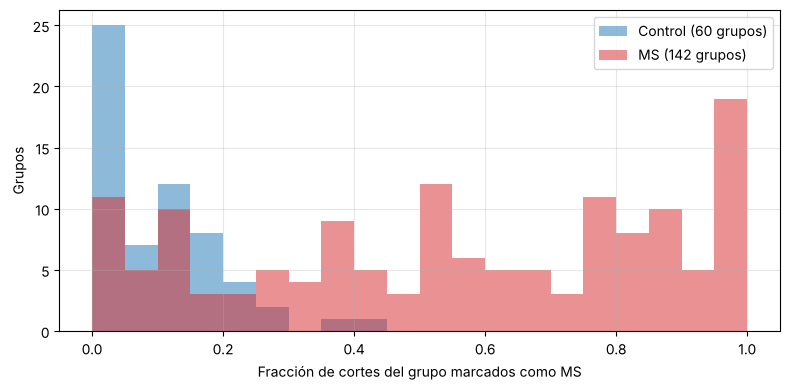

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 21)
for clase, color, c in [("Control", "tab:blue", 0), ("MS", "tab:red", 1)]:
    ax.hist(grp.loc[grp["y"] == c, "frac"], bins=bins, alpha=0.5, color=color, label=f"{clase} ({(grp['y'] == c).sum()} grupos)")
ax.set_xlabel("Fracción de cortes del grupo marcados como MS"); ax.set_ylabel("Grupos")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

&ensp; En la práctica el diagnóstico es por paciente. Para cada grupo se calculó la **fracción de sus cortes que la regla marca como MS** (con las predicciones de la validación). Un grupo se clasifica como MS si esa fracción supera el percentil 95 de las fracciones de los grupos Control de entrenamiento; el umbral quedó entre 0,25 y 0,27 según la partición. Es el mismo criterio que a nivel de corte.

| Nivel | n | Sensibilidad | Especificidad | Exactitud balanceada |
|---|---|---|---|---|
| Corte | 2760 | 0,531 | 0,903 | 0,717 |
| Grupo | 202 | 0,761 | 0,950 | 0,855 |

&ensp; Usando la fracción como puntaje, el AUC por grupo es 0,875. Al agregar los cortes de cada grupo, la sensibilidad sube de 0,53 a 0,76 y la especificidad de 0,90 a 0,95: aunque la regla falla en muchos cortes individuales, la proporción de cortes positivos sí distingue bastante bien los grupos de MS (108 de 142 detectados) de los de Control (3 falsos positivos de 60).

**Limitaciones (importantes para no sobreinterpretar).**
- **Los grupos de MS no son pacientes reales** (5.1): esto es el rendimiento por bloque de archivos consecutivos, no por paciente.
- **Los grupos de Control promedian unos 27 cortes y los de MS unos 9.** Con más cortes, la fracción es más estable, lo que favorece la especificidad.
- El n es chico: 60 grupos de Control, así que cada grupo mal clasificado cambia la especificidad en 1,7 puntos porcentuales.